# Part 4 — Feature Pipeline

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Construct a verified bank–decision-quarter feature table and four-quarter outcome. Financial information is selected as of the decision date; future event evidence is restricted to outcome adjudication. The notebook does not evaluate a model on the historical test.

## 1. Repository and runtime
Use a fresh CPU runtime. Java is required by the complete repository test suite.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, shutil
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
java = shutil.which("java")
if java is None:
    raise RuntimeError("Java 17 or later is required")
os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
print(subprocess.run([java,"-version"],check=True,capture_output=True,text=True).stderr)
subprocess.run([sys.executable,"-m","pip","install","-r",str(REPO/"requirements.txt")],check=True)
def command(script,*args):
    result = subprocess.run([sys.executable,str(REPO/script),*map(str,args)],cwd=REPO,text=True,capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

Git revision: 6dfcc483142f62bb15eb1721e4413e33defcfe6f
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



## 2. Mandatory offline validation
Run all repository tests, including Parquet and Spark integration. Do not proceed after a failure or skipped test.

In [2]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path("/content/part4_tests.xml")
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable,"-m","pytest","-q","-ra","--tb=short","--show-capture=no",f"--junitxml={result_path}","tests"],cwd=REPO,env=dict(os.environ,PYTEST_DISABLE_PLUGIN_AUTOLOAD="1",SPARK_LOCAL_IP="127.0.0.1",PYSPARK_PYTHON=sys.executable),capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
if not result_path.is_file(): raise RuntimeError("Missing pytest report")
cases=list(ET.parse(result_path).getroot().iter("testcase"))
problems=[(case,node) for case in cases for node in list(case) if node.tag in ("failure","error","skipped")]
for case,node in problems:
    print(case.get("classname"),case.get("name"),node.tag,node.get("message"),node.text or "")
if result.returncode or not cases or problems: raise RuntimeError("Offline validation failed; inspect diagnostics")
TESTS_PASSED=True
print(f"Mandatory offline validation: PASS ({len(cases)} tests, zero skips)")

........................................................................ [ 65%]
......................................                                   [100%]
----------------- generated xml file: /content/part4_tests.xml -----------------
110 passed in 199.25s (0:03:19)

Mandatory offline validation: PASS (110 tests, zero skips)


## 3. Verified upstream input
The Gold layer uses the original Silver panel and dated event ledger. Processing benchmarks inform the engine choice but are not feature data.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
WORKSPACE=Path('/content/drive/MyDrive/11230945')
assert TESTS_PASSED
assert not (WORKSPACE/'pending_source.json').exists()
command('run_part2.py','verify','--workspace',WORKSPACE)
pointer=json.loads((WORKSPACE/'active_panel.json').read_text())
SILVER=WORKSPACE/pointer['path']
silver_manifest=json.loads((SILVER/'manifest.json').read_text())
assert silver_manifest['state']=='VERIFIED'
print('Silver manifest:',pointer['manifest_sha256'])
print('Verified source rows:',f"{silver_manifest['summary']['panel_rows']:,}")
print('Financial report quarters:',silver_manifest['summary']['quarters'])
processing_pointer=WORKSPACE/'active_processing.json'
if processing_pointer.exists():
    pp=json.loads(processing_pointer.read_text())
    pm=json.loads((WORKSPACE/pp['path']/'manifest.json').read_text())
    assert pm['silver_manifest_sha256']==pointer['manifest_sha256']
    print('Part 3 lineage agrees with Silver; benchmark data are not used.')
else:
    print('Part 3 evidence pointer not present; no benchmark data are required by Gold.')

Mounted at /content/drive
{
  "status": "PASS",
  "path": "/content/drive/MyDrive/11230945/silver/2026-11-25T185119_525029Z_4385534b",
  "summary": {
    "asset_to_null": 0,
    "availability_assumption_days": 90,
    "bronze_failure_rows": 4117,
    "bronze_institution_rows": 27838,
    "distinct_certs": 24064,
    "event_diagnostics": {
      "assistance_records": 593,
      "duplicated_fin_values": 61,
      "end_dates_after_study_end": 4284,
      "failure_dates_before_first_report": 2,
      "failure_dates_before_last_report": 272,
      "failure_type_records": 3524,
      "invalid_or_missing_failure_dates": 0,
      "linked_distinct_failure_cert_dates_through_study_end": 2842,
      "linked_distinct_failure_certs_through_study_end": 2839,
      "missing_cert_failure_source_records": 488,
      "nonpositive_cert_failure_source_records": 0,
      "source_failure_records": 4117,
      "unknown_resolution_records": 0,
      "unknown_resolution_values": [],
      "unlinked_failure_typ

## 4. Fixed information and split protocol
Decision dates use the latest report available under the 90-day assumption, with a maximum two-quarter age. Exact historical lags are relative to the selected reporting date. The four-quarter label starts at the decision date. The split is fixed before construction, and the 2008–2014 period is reserved as a chronological out-of-time holdout. Its retrospective nature does not establish prospective performance.

In [4]:
sys.path.insert(0,str(REPO/'src'))
from fdic_ews.features.policy import *
from fdic_ews.features.financial import FEATURES,DETAILS
from fdic_ews.features.pipeline import COLUMNS
import pandas as pd
import numpy as np
from IPython.display import display
assert_split()
protocol=pd.DataFrame([
    ('Training','1984Q1–2000Q4'),('Purge','2001Q1–2001Q4'),
    ('Validation','2002Q1–2006Q4'),('Purge','2007Q1–2007Q4'),
    ('Historical test','2008Q1–2014Q4'),('Unused post-test','2015Q1–2025Q2')],columns=['Role','Decision quarters'])
display(protocol)
print('Raw predictor count:',len(FEATURES))
print('Gold columns:',len(COLUMNS))
print('Availability lag:',LAG,'days; maximum report age:',MAX_AGE,'quarters')
print('Last decision:',LAST,'; latest outcome:',STUDY_END)

,Role,Decision quarters
0,Training,1984Q1–2000Q4
1,Purge,2001Q1–2001Q4
2,Validation,2002Q1–2006Q4
3,Purge,2007Q1–2007Q4
4,Historical test,2008Q1–2014Q4
5,Unused post-test,2015Q1–2025Q2


Raw predictor count: 29
Gold columns: 38
Availability lag: 90 days; maximum report age: 2 quarters
Last decision: 2025-06-30 ; latest outcome: 2026-06-30


## 5. Build and independently verify Gold
The build publishes an active pointer only after all evidence and the 50-failure gate pass. It does not modify upstream data. The verify command recomputes feature and outcome tables from Silver. A rerun creates a separate Gold run.

In [5]:
def stream_command(script,*args):
    proc=subprocess.Popen([sys.executable,str(REPO/script),*map(str,args)],cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in proc.stdout:
        print(line,end='',flush=True)
    if proc.wait()!=0: raise RuntimeError(f'{script} failed; inspect the preceding output')
stream_command('run_part4.py','build','--workspace',WORKSPACE)
stream_command('run_part4.py','verify','--workspace',WORKSPACE)
feature_pointer=json.loads((WORKSPACE/'active_features.json').read_text())
GOLD=WORKSPACE/feature_pointer['path']
gold_manifest=json.loads((GOLD/'manifest.json').read_text())
assert gold_manifest['state']=='VERIFIED'
assert gold_manifest['silver_manifest_sha256']==pointer['manifest_sha256']
print('Gold manifest:',feature_pointer['manifest_sha256'])
print(json.dumps(gold_manifest['summary'],indent=2))

20 decision quarters verified: 1988-12-31
40 decision quarters verified: 1993-12-31
60 decision quarters verified: 1998-12-31
80 decision quarters verified: 2003-12-31
100 decision quarters verified: 2008-12-31
120 decision quarters verified: 2013-12-31
140 decision quarters verified: 2018-12-31
160 decision quarters verified: 2023-12-31
166 decision quarters verified: 2025-06-30
{
  "status": "PASS",
  "path": "/content/drive/MyDrive/11230945/gold/2026-11-25T203620_525161Z_e4f52492",
  "summary": {
    "test_distinct_failure_certs_in_calendar_period": 505,
    "test_distinct_failure_events_in_calendar_period": 505,
    "test_distinct_positive_events_through_final_horizon": 513,
    "risk_rows": 1640991,
    "labelled_rows": 1573640,
    "decision_quarters": 166,
    "feature_count": 29,
    "test_linked_failure_events_in_calendar_period": 505,
    "test_unrepresented_linked_failure_events_in_calendar_period": 0
  },
  "policy": {
    "lag_days": 90,
    "max_report_age_quarters": 2,
 

## 6. Risk-set, label and split accounting
Positive bank–quarters can refer to the same failure. Distinguish them from distinct CERT/date events and distinct institutions. The holdout is inspected only for accounting, class presence and the required failure count. Censored and unused rows remain in Gold.

In [6]:
audit=pd.read_csv(GOLD/'quarter_audit.csv')
splits=pd.read_csv(GOLD/'split_summary.csv')
reasons=pd.read_csv(GOLD/'label_reasons.csv')
order=['train','purge_train_validation','validation','purge_development_test','test','unused_post_test']
splits=splits.set_index('split').loc[order].reset_index()
assert (audit.candidate_rows==audit.risk_rows+audit.prior_exit+audit.prior_exit_conflict+audit.report_unavailable_or_stale).all()
assert (audit.risk_rows==audit.labelled+audit.censored).all()
assert (audit.labelled==audit.positive+audit.negative).all()
summary=gold_manifest['summary']
assert summary['test_distinct_failure_certs_in_calendar_period']>=MIN_TEST_FAILURES
print('Table 1. Decision-quarter population and outcome accounting')
display(splits[['split','candidate_rows','risk_rows','labelled','positive','negative','censored','distinct_positive_events','distinct_positive_certs']])
print('Table 2. Test-calendar failure-count gate')
display(pd.DataFrame([{'linked_events':summary['test_linked_failure_events_in_calendar_period'],'represented_events':summary['test_distinct_failure_events_in_calendar_period'],'represented_failure_CERTs':summary['test_distinct_failure_certs_in_calendar_period'],'unrepresented_linked_events':summary['test_unrepresented_linked_failure_events_in_calendar_period']}]))
print('Table 3. Development outcome reasons')
dev_reasons=reasons[reasons.split.isin(['train','validation'])].pivot_table(index='reason',columns='split',values='rows',aggfunc='sum',fill_value=0)
display(dev_reasons)

Table 1. Decision-quarter population and outcome accounting


,split,candidate_rows,risk_rows,labelled,positive,negative,censored,distinct_positive_events,distinct_positive_certs
0,train,974603,948824,906299,7718,898581,42525,1961,1961
1,purge_train_validation,40111,39223,37597,39,37558,1626,14,14
2,validation,186271,182958,176285,45,176240,6673,15,15
3,purge_development_test,35277,34581,33303,49,33254,1278,27,27
4,test,216889,212570,205672,2007,203665,6898,513,513
5,unused_post_test,227113,222835,214484,132,214352,8351,36,36


Table 2. Test-calendar failure-count gate


,linked_events,represented_events,represented_failure_CERTs,unrepresented_linked_events
0,505,505,505,0


Table 3. Development outcome reasons


split,train,validation
reason,,
conflicting_exit_evidence,4,7
conflicting_failure_evidence,1119,0
failure_within_horizon,7718,45
incomplete_followup,1128,225
multiple_in_horizon_events,2,0
observed_at_horizon,898581,176240
unconfirmed_competing_exit,40272,6441


## 7. Temporal and financial feature diagnostics
Feature formulas are fixed independently of test results. Training diagnostics include missingness, constants and the capital-zero treatment. Conditional YTD flow candidates are not predictors.

Table 4. Economic feature dictionary


,feature,group,formula,rationale
0,LOG_ASSET,size,"log1p(ASSET), ASSET > 0",Bank scale
1,EQUITY_ASSETS_PCT,capital,100 * EQ / ASSET,Loss absorption
2,TANGIBLE_EQUITY_ASSETS_PCT,capital,100 * (EQ - INTAN) / ASSET,Tangible loss absorption
3,DEPOSITS_ASSETS_PCT,funding,100 * DEP / ASSET,Deposit funding dependence
4,CASH_ASSETS_PCT,liquidity,100 * CHBAL / ASSET,Cash buffer
5,SECURITIES_ASSETS_PCT,liquidity,100 * SC / ASSET,"Securities allocation, not necessarily liquid"
6,LOANS_ASSETS_PCT,asset_quality,100 * LNLSGR / ASSET,Credit concentration
7,BROKERED_DEPOSITS_PCT,funding,100 * BRO / DEP,Wholesale funding dependence
8,LOANS_DEPOSITS_PCT,liquidity,100 * LNLSGR / DEP,Loan funding pressure
9,NONCURRENT_LOANS_PCT,asset_quality,100 * NCLNLS / LNLSGR,Noncurrent credit exposure


Table 5. Training feature quality


,feature,train_rows,missing,missing_pct,distinct_nonnull,missing_if_capital_zeros_masked
22,ROA_CHANGE_YOY_PPT,906299,84713,9.347,819376,84713
21,ASSET_GROWTH_YOY_PCT,906299,84713,9.347,817347,84713
20,DEPOSIT_GROWTH_QOQ_PCT,906299,25720,2.838,870603,25720
19,ASSET_GROWTH_QOQ_PCT,906299,21585,2.382,876134,21585
24,PRIOR_GAP_QUARTERS,906299,21553,2.378,7,21553
7,BROKERED_DEPOSITS_PCT,906299,18710,2.064,80138,18710
11,TEXAS_LIKE_PCT,906299,16400,1.810,731586,16400
13,ROE_PCT,906299,10678,1.178,23293,10678
9,NONCURRENT_LOANS_PCT,906299,8383,0.925,795701,8383
10,ALLOWANCE_LOANS_PCT,906299,8132,0.897,798885,8132


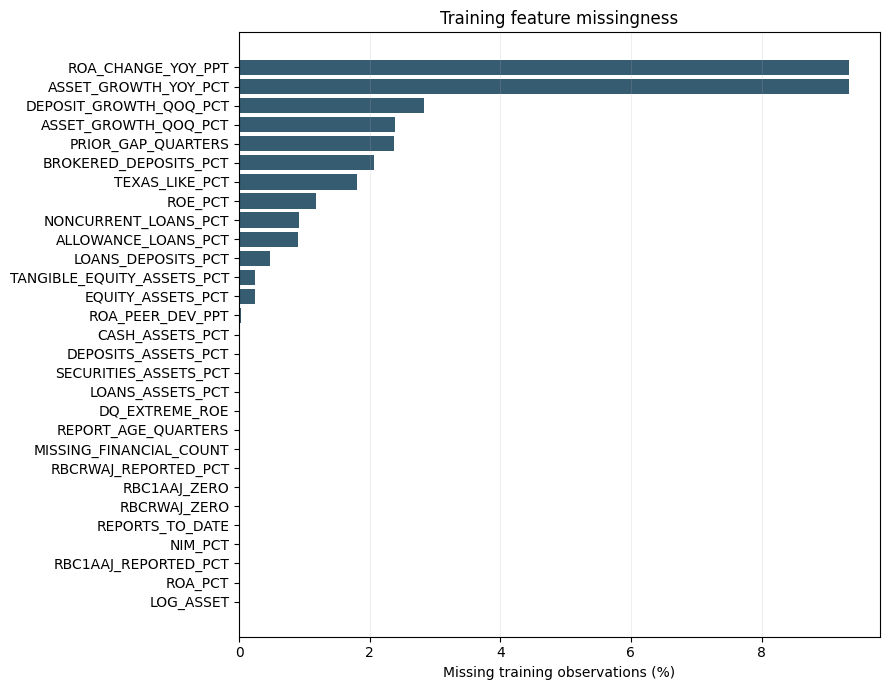

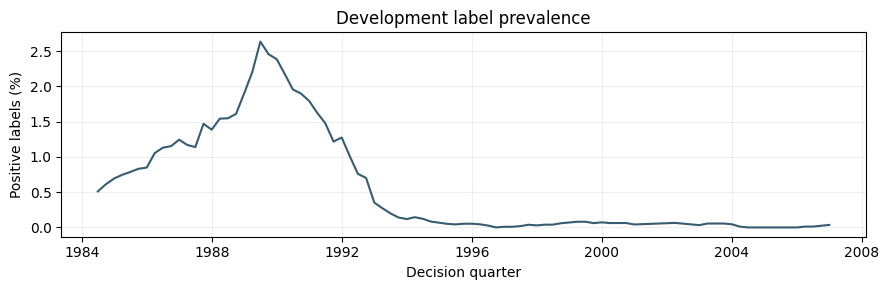

In [7]:
dictionary=pd.read_csv(GOLD/'feature_dictionary.csv')
quality=pd.read_csv(GOLD/'training_feature_quality.csv')
assert dictionary.feature.tolist()==list(FEATURES)
print('Table 4. Economic feature dictionary')
display(dictionary)
print('Table 5. Training feature quality')
display(quality.sort_values('missing_pct',ascending=False).round({'missing_pct':3}))
import matplotlib.pyplot as plt
train_missing=quality.sort_values('missing_pct',ascending=True)
fig,ax=plt.subplots(figsize=(9,7))
ax.barh(train_missing.feature,train_missing.missing_pct,color='#365c72')
ax.set(xlabel='Missing training observations (%)',title='Training feature missingness')
ax.grid(axis='x',alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)
# Development-only evolution; holdout is not used for feature diagnostics.
dev=audit[audit.split.isin(['train','validation'])].copy(); dev['date']=pd.to_datetime(dev.decision_date)
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(dev.date,100*dev.positive/dev.labelled.replace(0,np.nan),color='#365c72')
ax.set(xlabel='Decision quarter',ylabel='Positive labels (%)',title='Development label prevalence'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)

## 8. Training-only preprocessing and sensitivity
The fitted pipelines are demonstrations of the initial training-only fit. No holdout feature distributions, holdout transformations or model scores are used to choose a treatment. Development sensitivity quantifies candidate coverage under a 120-day lag and additional negatives under the unconfirmed-exit assumption.

In [8]:
prep=json.loads((GOLD/'preprocessing.json').read_text())
print('Table 6. Training-only preprocessing')
rows=[]
for name,info in prep.items():
    assert info['training_max']<=str(TRAIN_END)
    rows.append({'specification':name,'training_rows':info['training_rows'],'first_training_decision':info['training_min'],'last_training_decision':info['training_max'],'raw_features':len(info['feature_names']),'transformed_features':len(info['transformed_names']),'missing_indicators':len(info['missing_indicators']),'all_null_features':', '.join(info['all_null_features']) or 'None','constant_or_empty':', '.join(info['constant_or_empty_features']) or 'None'})
display(pd.DataFrame(rows))
print('Table 7. Capital-zero sensitivity (training)')
from fdic_ews.features.financial import CAPITAL
cap=quality[quality.feature.isin(CAPITAL)].copy()
cap['missing_if_masked_pct']=100*cap.missing_if_capital_zeros_masked/cap.train_rows
display(cap[['feature','train_rows','missing_pct','missing_if_masked_pct']].round(3))
print('Table 8. Development-only coverage and candidate-exit sensitivity')
display(dev.groupby('split',sort=False)[['candidate_rows','lag120_candidate_rows','candidate_exit_zero_extra_negatives']].sum().astype('int64').reset_index())
print('No treatment is chosen using test performance.')

Table 6. Training-only preprocessing


,specification,training_rows,first_training_decision,last_training_decision,raw_features,transformed_features,missing_indicators,all_null_features,constant_or_empty
0,capital_zero_as_missing,906299,1984-06-30,2000-12-31,29,49,20,None,None
1,primary,906299,1984-06-30,2000-12-31,29,47,18,None,None


Table 7. Capital-zero sensitivity (training)


,feature,train_rows,missing_pct,missing_if_masked_pct
15,RBC1AAJ_REPORTED_PCT,906299,0.0,7.950
16,RBCRWAJ_REPORTED_PCT,906299,0.0,44.269


Table 8. Development-only coverage and candidate-exit sensitivity


,split,candidate_rows,lag120_candidate_rows,candidate_exit_zero_extra_negatives
0,train,974603,951915,40272
1,validation,186271,185528,6441


No treatment is chosen using test performance.


## 9. Source-linked temporal case and handoff
CERT 7213 illustrates the distinction between a decision date and the source report. The Part 2 audit identifies assistance outside the 2006Q4 four-quarter outcome horizon. Inspect only this development case; no holdout scores are produced.

In [9]:
import pyarrow.parquet as pq
case_date='2006-12-31'
e=gold_manifest['panel'][case_date]
case=pq.ParquetFile(GOLD/e['path']).read(columns=['CERT','DECISION_DATE','REPORT_DATE','AVAILABLE_AT','HORIZON_END','Y_FAIL_4Q','LABEL_REASON']).to_pandas()
case=case.loc[case.CERT.eq(7213)]
if not case.empty:
    display(case)
    assert pd.to_datetime(case.AVAILABLE_AT).le(pd.to_datetime(case.DECISION_DATE)).all()
    assert pd.to_datetime(case.HORIZON_END).eq(pd.Timestamp('2007-12-31')).all()
else:
    print('CERT 7213 not in this decision risk set; inspect the verified source and risk accounting.')
print('Gold state:',gold_manifest['state'])
print('Decision quarters:',summary['decision_quarters'])
print('Risk rows:',f"{summary['risk_rows']:,}")
print('Labelled rows:',f"{summary['labelled_rows']:,}")
print('Model evaluation: NOT PERFORMED')
print('Part 5 input pointer:',WORKSPACE/'active_features.json')

,CERT,DECISION_DATE,REPORT_DATE,AVAILABLE_AT,HORIZON_END,Y_FAIL_4Q,LABEL_REASON
1651,7213,2006-12-31,2006-09-30,2006-12-29,2007-12-31,0.0,observed_at_horizon


Gold state: VERIFIED
Decision quarters: 166
Risk rows: 1,640,991
Labelled rows: 1,573,640
Model evaluation: NOT PERFORMED
Part 5 input pointer: /content/drive/MyDrive/11230945/active_features.json


## 10. Handoff
Part 5 reads the verified raw Gold table and uses the ordered predictor allowlist. Fit a fresh preprocessing pipeline inside each chronological fold, lock the feature/model/threshold choices on development, and evaluate the fixed historical test once. Candidate-exit, lag and capital-zero sensitivity are not selected using test scores. Save this executed notebook to the repository with its outputs. Keep all data and serialized estimators in the workspace.

See `docs/part4_protocol.md` for the complete methodology, assumptions, limitations and references.